# Préparation des données pour l'étude de marché pour développement à l'international

## Importation des librairies

In [ ]:
#Importation des librairies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import csv

## Chargement des fichiers

In [ ]:
#Lien permettant d'accéder à mon Google Drive ou sont stocker mes fichiers
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#Importation du fichier DisponibiliteAlimentaire_2017.csv
Disponibilite = pd.read_csv('/content/drive/MyDrive/Projet_11_data/DisponibiliteAlimentaire_2017.csv', sep=",")

#Importation du fichier indiceLogistiques_2018_clean.csv
Logistique = pd.read_csv('/content/drive/MyDrive/Projet_11_data/indiceLogistiques_2018.csv',
                         sep=",",
                         na_values=[".."],
                         engine="python",
                         on_bad_lines="skip")

#Importation du fichier Inflation_2007_2017.csv
Inflation = pd.read_csv('/content/drive/MyDrive/Projet_11_data/Inflation_2007_2017.csv',
                        sep=",",
                        na_values=[".."],
                        engine="python",
                        on_bad_lines="skip",
                        encoding="latin1")

#Importation du fichier Population_2000_2018.csv
Population = pd.read_csv('/content/drive/MyDrive/Projet_11_data/Population_2000_2018.csv', sep=",")

#Importation du fichier SecuriteAlimentaire_2017.csv
SecuriteAlimentaire = pd.read_csv('/content/drive/MyDrive/Projet_11_data/SecuriteAlimentaire_2017.csv', sep=",")

#Importation du fichier GNI_Per_Capita_PPP_2017.csv
Revenu = pd.read_csv('/content/drive/MyDrive/Projet_11_data/GNI_Per_Capita_PPP_2017.csv',
                                 sep=",",
                                 na_values=[".."],
                                 engine="python",
                                 on_bad_lines="skip",
                                 encoding="latin1")

## Analyse exploratoire et premier nettoyage

### Fichier de Disponibilité alimentaire

In [ ]:
# Première observation des données
Disponibilite.head()

,Code Domaine,Domaine,Code zone,Zone,Code Élément,Élément,Code Produit,Produit,Code année,Année,Unité,Valeur,Symbole,Description du Symbole
0,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5511,Production,2511,Blé et produits,2017,2017,Milliers de tonnes,4281.0,S,Données standardisées
1,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5611,Importations - Quantité,2511,Blé et produits,2017,2017,Milliers de tonnes,2302.0,S,Données standardisées
2,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5072,Variation de stock,2511,Blé et produits,2017,2017,Milliers de tonnes,-119.0,S,Données standardisées
3,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5911,Exportations - Quantité,2511,Blé et produits,2017,2017,Milliers de tonnes,0.0,S,Données standardisées
4,FBS,Nouveaux Bilans Alimentaire,2,Afghanistan,5301,Disponibilité intérieure,2511,Blé et produits,2017,2017,Milliers de tonnes,6701.0,S,Données standardisées


Je n'ai pas besoin de toute ces données. Je vais conserver les pays, l'élément, le produit 'Viande de Volailles', unité et valeur.

In [ ]:
#Filtre sur Volaille et conservation des colonnes nécessaire à l'étude
Disponibilite_clean = Disponibilite[Disponibilite['Produit'] == 'Viande de Volailles'][['Zone', 'Élément', 'Unité', 'Valeur']]
display(Disponibilite_clean.head(10))

,Zone,Élément,Unité,Valeur
651,Afghanistan,Production,Milliers de tonnes,28.00
652,Afghanistan,Importations - Quantité,Milliers de tonnes,29.00
653,Afghanistan,Variation de stock,Milliers de tonnes,0.00
654,Afghanistan,Disponibilité intérieure,Milliers de tonnes,57.00
655,Afghanistan,Pertes,Milliers de tonnes,2.00
656,Afghanistan,Résidus,Milliers de tonnes,0.00
657,Afghanistan,Nourriture,Milliers de tonnes,55.00
658,Afghanistan,Disponibilité alimentaire en quantité (kg/pers...,kg,1.53
659,Afghanistan,Disponibilité alimentaire (Kcal/personne/jour),Kcal/personne/jour,5.00
660,Afghanistan,Disponibilité de protéines en quantité (g/pers...,g/personne/jour,0.54


In [ ]:
#Voir les variables des éléments différents
Disponibilite_clean['Élément'].unique()

array(['Production', 'Importations - Quantité', 'Variation de stock',
       'Disponibilité intérieure', 'Pertes', 'Résidus', 'Nourriture',
       'Disponibilité alimentaire en quantité (kg/personne/an)',
       'Disponibilité alimentaire (Kcal/personne/jour)',
       'Disponibilité de protéines en quantité (g/personne/jour)',
       'Disponibilité de matière grasse en quantité (g/personne/jour)',
       'Exportations - Quantité', 'Alimentation pour touristes',
       'Traitement', 'Autres utilisations (non alimentaire)',
       'Aliments pour animaux', 'Semences'], dtype=object)

Il me faudra, pour mon étude,connaitre la dépendance alimentaire des pays

In [ ]:
dispo_pivot = Disponibilite_clean.pivot_table(index='Zone', columns='Élément', values='Valeur').reset_index()

# Calcul de la  DependanceAlimentaire par pays pour la volaille
dispo_pivot['Dependance Alimentaire'] = (dispo_pivot['Importations - Quantité'] / dispo_pivot['Disponibilité intérieure']) * 100

dispo_pivot_clean = dispo_pivot[['Zone', 'Importations - Quantité', 'Disponibilité intérieure', 'Dependance Alimentaire']]
display(dispo_pivot_clean.head())

Élément,Zone,Importations - Quantité,Disponibilité intérieure,Dependance Alimentaire
0,Afghanistan,29.0,57.0,50.877193
1,Afrique du Sud,514.0,2118.0,24.268178
2,Albanie,38.0,47.0,80.851064
3,Algérie,2.0,277.0,0.722022
4,Allemagne,842.0,1739.0,48.418631


In [ ]:
#Renommer "Zone" en "Pays"
dispo_pivot_clean = dispo_pivot_clean.rename(columns={'Zone': 'Pays'})
display(dispo_pivot_clean.head(2))

Élément,Pays,Importations - Quantité,Disponibilité intérieure,Dependance Alimentaire
0,Afghanistan,29.0,57.0,50.877193
1,Afrique du Sud,514.0,2118.0,24.268178


Je vais également renommer des pays pour pouvoir par la suite faire le lien plus facilement avec mes autres bases de données

In [ ]:
# Renommer 'Bolivie (État plurinational de)' en 'Bolivie'
dispo_pivot_clean['Pays'] = dispo_pivot_clean['Pays'].replace('Bolivie (État plurinational de)', 'Bolivie')

#Renommer 'Iran (République islamique d')' en'Iran'
dispo_pivot_clean['Pays'] = dispo_pivot_clean['Pays'].replace("Iran (République islamique d')", 'Iran')

# Vérifier le changement
print("Vérification du renommage pour 'Bolivie':")
display(dispo_pivot_clean[dispo_pivot_clean['Pays'].str.contains('Bolivie', na=False)])

print("Vérification du renommage pour 'Iran':")
display(dispo_pivot_clean[dispo_pivot_clean['Pays'].str.contains('Iran', na=False)])

Vérification du renommage pour 'Bolivie':


Élément,Pays,Importations - Quantité,Disponibilité intérieure,Dependance Alimentaire
18,Bolivie,1.0,429.0,0.2331


Vérification du renommage pour 'Iran':


Élément,Pays,Importations - Quantité,Disponibilité intérieure,Dependance Alimentaire
68,Iran,6.0,2220.0,0.27027


### Fichier Population

In [ ]:
Population.head(5)

,Code Domaine,Domaine,Code zone,Zone,Code Élément,Élément,Code Produit,Produit,Code année,Année,Unité,Valeur,Symbole,Description du Symbole,Note
0,OA,Séries temporelles annuelles,2,Afghanistan,511,Population totale,3010,Population-Estimations,2000,2000,1000 personnes,20779.953,X,Sources internationales sûres,NaN
1,OA,Séries temporelles annuelles,2,Afghanistan,511,Population totale,3010,Population-Estimations,2001,2001,1000 personnes,21606.988,X,Sources internationales sûres,NaN
2,OA,Séries temporelles annuelles,2,Afghanistan,511,Population totale,3010,Population-Estimations,2002,2002,1000 personnes,22600.770,X,Sources internationales sûres,NaN
3,OA,Séries temporelles annuelles,2,Afghanistan,511,Population totale,3010,Population-Estimations,2003,2003,1000 personnes,23680.871,X,Sources internationales sûres,NaN
4,OA,Séries temporelles annuelles,2,Afghanistan,511,Population totale,3010,Population-Estimations,2004,2004,1000 personnes,24726.684,X,Sources internationales sûres,NaN


In [ ]:
#Afficher les variables différentes dans la colonne élément
Population['Élément'].unique()

array(['Population totale'], dtype=object)

In [ ]:
#Afficher les variables différentes dans la colonne produit
Population['Produit'].unique()

array(['Population-Estimations'], dtype=object)

Conservons les données nécessaires à nos traitements (études et calcule)

In [ ]:
Population_clean = Population[['Zone', 'Année', 'Unité', 'Valeur']]
display(Population_clean.head())

,Zone,Année,Unité,Valeur
0,Afghanistan,2000,1000 personnes,20779.953
1,Afghanistan,2001,1000 personnes,21606.988
2,Afghanistan,2002,1000 personnes,22600.770
3,Afghanistan,2003,1000 personnes,23680.871
4,Afghanistan,2004,1000 personnes,24726.684


Je vais maintenant faire quelques calcules avant de filtrer sur l'année 2017. Je vais avoir besoin de calculer la croissance démographique. Prenons sur 5 ans. Nous multiplierons également les populations par 1000.

In [ ]:
# Filtrer les données de population pour les années 2012 et 2017
population_2012 = Population_clean[Population_clean['Année'] == 2012][['Zone', 'Valeur']].rename(columns={'Valeur': 'Valeur_2012'})
population_2017 = Population_clean[Population_clean['Année'] == 2017][['Zone', 'Valeur']].rename(columns={'Valeur': 'Population_2017'})

# Multiplier les valeurs par 1000
population_2012['Valeur_2012'] = population_2012['Valeur_2012'] * 1000
population_2017['Population_2017'] = population_2017['Population_2017'] * 1000

# Fusionner les deux DataFrames sur la colonne 'Zone'
population_growth = pd.merge(population_2012, population_2017, on='Zone', how='inner')

# Calculer la croissance démographique
population_growth['CroissanceDemo'] = ((population_growth['Population_2017'] - population_growth['Valeur_2012']) / population_growth['Valeur_2012']) * 100

#Renommer "Zone" en "Pays"
population_growth = population_growth.rename(columns={'Zone': 'Pays'})


# Suppression colonne valeur_2012
population_growth = population_growth.drop(columns=['Valeur_2012'])

# Afficher les premières lignes du résultat
display(population_growth.head())

,Pays,Population_2017,CroissanceDemo
0,Afghanistan,36296113.0,16.477889
1,Afrique du Sud,57009756.0,7.906280
2,Albanie,2884169.0,-1.026974
3,Algérie,41389189.0,10.713956
4,Allemagne,82658409.0,2.081915


La encore, je renomme quelques pays pour pouvoir mieux coller à mes autres données

In [ ]:
# Renommer 'Bolivie (État plurinational de)' en 'Bolivie'
population_growth['Pays'] = population_growth['Pays'].replace('Bolivie (État plurinational de)', 'Bolivie')

#Renommer 'Iran (République islamique d')' en'Iran'
population_growth['Pays'] = population_growth['Pays'].replace("Iran (République islamique d')", 'Iran')

# Vérifier le changement
print("Vérification du renommage pour 'Bolivie':")
display(population_growth[population_growth['Pays'].str.contains('Bolivie', na=False)])

print("Vérification du renommage pour 'Iran':")
display(population_growth[population_growth['Pays'].str.contains('Iran', na=False)])

Vérification du renommage pour 'Bolivie':


,Pays,Population_2017,CroissanceDemo
27,Bolivie,11192855.0,7.855121


Vérification du renommage pour 'Iran':


,Pays,Population_2017,CroissanceDemo
105,Iran,80673883.0,6.796417


### Fichier logistique

In [ ]:
Logistique.head(5)

,Series Name,Series Code,Country Name,Country Code,2018 [YR2018]
0,Logistics performance index: Overall (1=low to...,LP.LPI.OVRL.XQ,Afghanistan,AFG,1.95
1,Logistics performance index: Overall (1=low to...,LP.LPI.OVRL.XQ,Albania,ALB,2.66
2,Logistics performance index: Overall (1=low to...,LP.LPI.OVRL.XQ,Algeria,DZA,2.45
3,Logistics performance index: Overall (1=low to...,LP.LPI.OVRL.XQ,American Samoa,ASM,NaN
4,Logistics performance index: Overall (1=low to...,LP.LPI.OVRL.XQ,Andorra,AND,NaN


Pour alleger les données, je decide de supprimer les pays qui ne comportent pas d'indice logistiques

In [ ]:
# Voir les pays qui n'ont pas d'indice Logistique
nan_logistics_countries = Logistique[Logistique['2018 [YR2018]'].isna()]['Country Name']

if not nan_logistics_countries.empty:
    print("Pays qui n'ont pas d'indice dans '2018 [YR2018]' dans le DF Logistique:")
    for country in nan_logistics_countries:
        print(f"- {country}")

    # Supprimer ces pays du DF
    Logistique = Logistique[~Logistique['Country Name'].isin(nan_logistics_countries)]
    print("\nCes pays ont été supprimés du dataframe Logistique.")
else:
    print("Tous les pays ont un indice logistique dans '2018 [YR2018]'.")

Pays qui n'ont pas d'indice dans '2018 [YR2018]' dans le DF Logistique:
- American Samoa
- Andorra
- Antigua and Barbuda
- Aruba
- Azerbaijan
- Barbados
- Belize
- Bermuda
- Botswana
- British Virgin Islands
- Cabo Verde
- Cayman Islands
- Channel Islands
- Curacao
- Dominica
- Eswatini
- Ethiopia
- Faroe Islands
- French Polynesia
- Gibraltar
- Greenland
- Grenada
- Guam
- Isle of Man
- Kiribati
- Korea, Dem. People's Rep.
- Kosovo
- Liechtenstein
- Macao SAR, China
- Marshall Islands
- Micronesia, Fed. Sts.
- Monaco
- Mozambique
- Namibia
- Nauru
- New Caledonia
- Nicaragua
- Northern Mariana Islands
- Palau
- Puerto Rico (US)
- Samoa
- San Marino
- Seychelles
- Sint Maarten (Dutch part)
- South Sudan
- St. Kitts and Nevis
- St. Lucia
- St. Martin (French part)
- St. Vincent and the Grenadines
- Suriname
- Tanzania
- Timor-Leste
- Tonga
- Turks and Caicos Islands
- Tuvalu
- Vanuatu
- Virgin Islands (U.S.)
- West Bank and Gaza
- Not classified
- nan
- nan
- nan
- nan
- nan

Ces pays o

Pour pouvoir faire la fusion des différents fichier, il faut traduire le nom des pays en francais.

In [ ]:
# Nettoyage initial
Logistique_clean = Logistique[['Country Name', '2018 [YR2018]']].rename(
    columns={'2018 [YR2018]': 'Indice Logistique', 'Country Name': 'Pays'}
)

# Mapping EN -> FR
mapping_fr = {
    "Africa Eastern and Southern": "Afrique de l'Est et australe",
    "Africa Western and Central": "Afrique de l'Ouest et centrale",
    "Albania": "Albanie",
    "Algeria": "Algérie",
    "American Samoa": "Samoa américaines",
    "Andorra": "Andorre",
    "Antigua and Barbuda": "Antigua-et-Barbuda",
    "Arab World": "Monde arabe",
    "Argentina": "Argentine",
    "Armenia": "Arménie",
    "Aruba": "Aruba",
    "Australia": "Australie",
    "Austria": "Autriche",
    "Azerbaijan": "Azerbaïdjan",
    "Bahamas, The": "Bahamas",
    "Bahrain": "Bahreïn",
    "Barbados": "Barbade",
    "Belarus": "Biélorussie",
    "Belgium": "Belgique",
    "Benin": "Bénin",
    "Bermuda": "Bermudes",
    "Bhutan": "Bhoutan",
    "Bolivia": "Bolivie",
    "Bosnia and Herzegovina": "Bosnie-Herzégovine",
    "Brazil": "Brésil",
    "British Virgin Islands": "Îles Vierges britanniques",
    "Brunei Darussalam": "Brunéi Darussalam",
    "Bulgaria": "Bulgarie",
    "Burundi": "Burundi",
    "Cambodia": "Cambodge",
    "Cameroon": "Cameroun",
    "Caribbean small states": "Petits États des Caraïbes",
    "Cayman Islands": "Îles Caïmans",
    "Central African Republic": "République centrafricaine",
    "Central Europe and the Baltics": "Europe centrale et pays baltes",
    "Chad": "Tchad",
    "Channel Islands": "Îles Anglo-Normandes",
    "Chile": "Chili",
    "China": "Chine, continentale",
    "Colombia": "Colombie",
    "Comoros": "Comores",
    "Congo, Dem. Rep.": "République démocratique du Congo",
    "Congo, Rep.": "Congo",
    "Cote d'Ivoire": "Côte d'Ivoire",
    "Croatia": "Croatie",
    "Curacao": "Curaçao",
    "Cyprus": "Chypre",
    "Czechia": "Tchéquie",
    "Denmark": "Danemark",
    "Dominica": "Dominique",
    "Dominican Republic": "République dominicaine",
    "Ecuador": "Équateur",
    "Egypt, Arab Rep.": "Égypte",
    "Equatorial Guinea": "Guinée équatoriale",
    "Eritrea": "Érythrée",
    "Estonia": "Estonie",
    "Ethiopia": "Éthiopie",
    "Euro area": "Zone euro",
    "Europe & Central Asia": "Europe et Asie centrale",
    "Europe & Central Asia (IDA & IBRD countries)": "Europe et Asie centrale (pays IDA & BIRD)",
    "Europe & Central Asia (excluding high income)": "Europe et Asie centrale (hors revenu élevé)",
    "European Union": "Union européenne",
    "Faroe Islands": "Îles Féroé",
    "Fiji": "Fidji",
    "Finland": "Finlande",
    "Fragile and conflict affected situations": "Situations fragiles et affectées par les conflits",
    "French Polynesia": "Polynésie française",
    "Gambia, The": "Gambie",
    "Georgia": "Géorgie",
    "Germany": "Allemagne",
    "Gibraltar": "Gibraltar",
    "Greece": "Grèce",
    "Greenland": "Groenland",
    "Grenada": "Grenade",
    "Guam": "Guam",
    "Guinea": "Guinée",
    "Guinea-Bissau": "Guinée-Bissau",
    "Haiti": "Haïti",
    "Heavily indebted poor countries (HIPC)": "Pays pauvres très endettés (PPTE)",
    "High income": "Revenu élevé",
    "Hong Kong SAR, China": "Chine - RAS de Hong-Kong",
    "Hungary": "Hongrie",
    "Iceland": "Islande",
    "India": "Inde",
    "Indonesia": "Indonésie",
    "Iran, Islamic Rep.": "Iran",
    "Ireland": "Irlande",
    "Isle of Man": "Île de Man",
    "Israel": "Israël",
    "Italy": "Italie",
    "Jamaica": "Jamaïque",
    "Japan": "Japon",
    "Jordan": "Jordanie",
    "Korea, Dem. People's Rep.": "République populaire démocratique de Corée",
    "Korea, Rep.": "République de Corée",
    "Kosovo": "Kosovo",
    "Kuwait": "Koweït",
    "Kyrgyz Republic": "Kirghizistan",
    "Lao PDR": "Laos",
    "Late-demographic dividend": "Dividende démographique tardif",
    "Latin America & Caribbean": "Amérique latine et Caraïbes",
    "Latin America & Caribbean (excluding high income)": "Amérique latine et Caraïbes (hors revenu élevé)",
    "Latin America & the Caribbean (IDA & IBRD countries)": "Amérique latine et Caraïbes (pays IDA & BIRD)",
    "Latvia": "Lettonie",
    "Least developed countries: UN classification": "Pays les moins avancés (ONU)",
    "Lebanon": "Liban",
    "Liberia": "Libéria",
    "Libya": "Libye",
    "Liechtenstein": "Liechtenstein",
    "Lithuania": "Lituanie",
    "Low & middle income": "Revenu faible et intermédiaire",
    "Low income": "Revenu faible",
    "Lower middle income": "Revenu intermédiaire inférieur",
    "Macao SAR, China": "Chine - RAS de Macao",
    "Malaysia": "Malaisie",
    "Malta": "Malte",
    "Marshall Islands": "Îles Marshall",
    "Mauritania": "Mauritanie",
    "Mauritius": "Maurice",
    "Mexico": "Mexique",
    "Micronesia, Fed. Sts.": "Micronésie",
    "Middle East, North Africa, Afghanistan & Pakistan": "MENA + Afghanistan & Pakistan",
    "Middle income": "Revenu intermédiaire",
    "Moldova": "République de Moldova",
    "Monaco": "Monaco",
    "Mongolia": "Mongolie",
    "Montenegro": "Monténégro",
    "Morocco": "Maroc",
    "Namibia": "Namibie",
    "Nauru": "Nauru",
    "Nepal": "Népal",
    "Netherlands": "Pays-Bas",
    "New Caledonia": "Nouvelle-Calédonie",
    "New Zealand": "Nouvelle-Zélande",
    "Nigeria": "Nigéria",
    "North America": "Amérique du Nord",
    "North Macedonia": "Macédoine du Nord",
    "Northern Mariana Islands": "Îles Mariannes du Nord",
    "Norway": "Norvège",
    "OECD members": "Membres de l'OCDE",
    "Other small states": "Autres petits États",
    "Pacific island small states": "Petits États insulaires du Pacifique",
    "Palau": "Palaos",
    "Papua New Guinea": "Papouasie-Nouvelle-Guinée",
    "Peru": "Pérou",
    "Poland": "Pologne",
    "Post-demographic dividend": "Post-dividende démographique",
    "Pre-demographic dividend": "Pré-dividende démographique",
    "Puerto Rico (US)": "Porto Rico",
    "Qatar": "Qatar",
    "Romania": "Roumanie",
    "Russian Federation": "Fédération de Russie",
    "San Marino": "Saint-Marin",
    "Sao Tome and Principe": "Sao Tomé-et-Principe",
    "Saudi Arabia": "Arabie saoudite",
    "Senegal": "Sénégal",
    "Serbia": "Serbie",
    "Seychelles": "Seychelles",
    "Singapore": "Singapour",
    "Sint Maarten (Dutch part)": "Saint-Martin (partie néerlandaise)",
    "Slovak Republic": "Slovaquie",
    "Slovenia": "Slovénie",
    "Small states": "Petits États",
    "Solomon Islands": "Îles Salomon",
    "Somalia, Fed. Rep.": "Somalie",
    "South Africa": "Afrique du Sud",
    "South Asia": "Asie du Sud",
    "South Sudan": "Soudan du Sud",
    "Spain": "Espagne",
    "St. Kitts and Nevis": "Saint-Christophe-et-Niévès",
    "St. Lucia": "Sainte-Lucie",
    "St. Martin (French part)": "Saint-Martin (partie française)",
    "St. Vincent and the Grenadines": "Saint-Vincent-et-les-Grenadines",
    "Sub-Saharan Africa": "Afrique subsaharienne",
    "Sudan": "Soudan",
    "Sweden": "Suède",
    "Switzerland": "Suisse",
    "Syrian Arab Republic": "Syrie",
    "Tajikistan": "Tadjikistan",
    "Tanzania": "Tanzanie",
    "Thailand": "Thaïlande",
    "Tonga": "Tonga",
    "Trinidad and Tobago": "Trinité-et-Tobago",
    "Tunisia": "Tunisie",
    "Turkiye": "Turquie",
    "Turkmenistan": "Turkménistan",
    "Turks and Caicos Islands": "Îles Turques-et-Caïques",
    "Tuvalu": "Tuvalu",
    "Uganda": "Ouganda",
    "United Arab Emirates": "Émirats arabes unis",
    "United Kingdom": "Royaume-Uni de Grande-Bretagne et d'Irlande du Nord",
    "United States": "États-Unis d'Amérique",
    "Upper middle income": "Revenu intermédiaire supérieur",
    "Uzbekistan": "Ouzbékistan",
    "Venezuela, RB": "Venezuela (République bolivarienne du)",
    "Virgin Islands (U.S.)": "Îles Vierges américaines",
    "West Bank and Gaza": "Cisjordanie et Gaza",
    "World": "Monde",
    "Yemen, Rep.": "Yémen",
    "Zambia": "Zambie"
}

# Application de la traduction
Logistique_clean['Pays_FR'] = Logistique_clean['Pays'].replace(mapping_fr)

display(Logistique_clean.head())


,Pays,Indice Logistique,Pays_FR
0,Afghanistan,1.95,Afghanistan
1,Albania,2.66,Albanie
2,Algeria,2.45,Algérie
5,Angola,2.05,Angola
7,Argentina,2.89,Argentine


In [ ]:
# Supprimer l'ancienne colonne Pays
Logistique_clean = Logistique_clean.drop(columns=['Pays'])

# Renommer Pays_FR en Pays
Logistique_clean = Logistique_clean.rename(columns={'Pays_FR': 'Pays'})

# Réordonner les colonnes pour mettre Pays en premier
colonnes = ['Pays'] + [col for col in Logistique_clean.columns if col != 'Pays']
Logistique_clean = Logistique_clean[colonnes]

display(Logistique_clean.head())


,Pays,Indice Logistique
0,Afghanistan,1.95
1,Albanie,2.66
2,Algérie,2.45
5,Angola,2.05
7,Argentine,2.89


### Fichier Inflation

In [ ]:
Inflation.head(5)

,Series Name,Series Code,Country Name,Country Code,2007 [YR2007],2017 [YR2017]
0,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,Afghanistan,AFG,8.680571,4.975952
1,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,Albania,ALB,2.932682,1.986661
2,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,Algeria,DZA,3.678996,5.591116
3,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,American Samoa,ASM,NaN,NaN
4,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,Andorra,AND,NaN,NaN


Ici aussi il faudra faire quelque modification et calculer la croissance de l'inflation, cette fois sur 10 ans pour évaluer la stabilité du pouvoir d'achat des pays

In [ ]:
#Conserver les colonnes Country Name, 2007 [YR2007] et 2017 [YR2017], en renommant dans celle ci "Pays", "2007" et "Inflation 2017"
Inflation_clean = Inflation[['Country Name', '2007 [YR2007]', '2017 [YR2017]']].rename(columns={'Country Name': 'Pays', '2007 [YR2007]': 'Inflation 2007', '2017 [YR2017]': 'Inflation 2017'})
display(Inflation_clean.head())

,Pays,Inflation 2007,Inflation 2017
0,Afghanistan,8.680571,4.975952
1,Albania,2.932682,1.986661
2,Algeria,3.678996,5.591116
3,American Samoa,NaN,NaN
4,Andorra,NaN,NaN


In [ ]:
# Filtrer les lignes où au moins une des colonnes est manquante
missing_inflation = Inflation_clean[
    Inflation_clean[['Inflation 2007', 'Inflation 2017']].isna().any(axis=1)
]

# Affichage
if missing_inflation.empty:
    print("Aucun pays n'a de valeur manquante dans Inflation 2007 ou Inflation 2017.")
else:
    print("Pays avec au moins une valeur manquante :")
    for pays in missing_inflation['Pays']:
        print(f"- {pays}")

Pays avec au moins une valeur manquante :
- American Samoa
- Andorra
- Argentina
- Bermuda
- British Virgin Islands
- Cayman Islands
- Channel Islands
- Congo, Dem. Rep.
- Cuba
- Eritrea
- Faroe Islands
- French Polynesia
- Gibraltar
- Greenland
- Guam
- Isle of Man
- Korea, Dem. People's Rep.
- Lebanon
- Liechtenstein
- Marshall Islands
- Monaco
- Nauru
- New Caledonia
- Northern Mariana Islands
- Puerto Rico (US)
- Somalia, Fed. Rep.
- South Sudan
- St. Martin (French part)
- Tajikistan
- Turkmenistan
- Turks and Caicos Islands
- Tuvalu
- United Arab Emirates
- Uzbekistan
- Venezuela, RB
- Virgin Islands (U.S.)
- Yemen, Rep.
- Zimbabwe
- Not classified
- nan
- nan
- nan
- nan
- nan


Je décide pour les pays si dessous de remplir à la main les données manquantes et facilements trouvables avec des sources fiables (Ici Banque mondiale)

In [ ]:
inflation_updates = {
    "Argentina": {"Inflation 2007": 10.9, "Inflation 2017": 26.9},
    "Congo, Dem. Rep.": {"Inflation 2007": 16.7, "Inflation 2017": 11.8},
    "Tajikistan": {"Inflation 2007": 13.2, "Inflation 2017": 7.3},
    "United Arab Emirates": {"Inflation 2007": 11.1, "Inflation 2017": 1.97},
    "Uzbekistan": {"Inflation 2007": 12.3, "Inflation 2017": 12.5},
    "Zimbabwe": {"Inflation 2007": 66212.3, "Inflation 2017": 0.9}
}

for pays, values in inflation_updates.items():
    Inflation_clean.loc[Inflation_clean['Pays'] == pays, 'Inflation 2007'] = values["Inflation 2007"]
    Inflation_clean.loc[Inflation_clean['Pays'] == pays, 'Inflation 2017'] = values["Inflation 2017"]


In [ ]:
# Calcule de la croissance de l'inflation
Inflation_clean['Croissance Inflation'] = ((Inflation_clean['Inflation 2017'] - Inflation_clean['Inflation 2007']))

display(Inflation_clean.head())

,Pays,Inflation 2007,Inflation 2017,Croissance Inflation
0,Afghanistan,8.680571,4.975952,-3.704619
1,Albania,2.932682,1.986661,-0.946021
2,Algeria,3.678996,5.591116,1.912120
3,American Samoa,NaN,NaN,NaN
4,Andorra,NaN,NaN,NaN


In [ ]:
#Voir le togo
inflation_togo = Inflation_clean[Inflation_clean['Pays'] == 'Togo']
print(inflation_togo)

     Pays  Inflation 2007  Inflation 2017  Croissance Inflation
194  Togo        0.945673        -0.98189             -1.927563


In [ ]:
#Suppression de la colonne inflation 2007
Inflation_clean = Inflation_clean.drop(columns=['Inflation 2007'])

In [ ]:
# Suppression les pays sans résultat
Inflation_clean = Inflation_clean[
        ~Inflation_clean['Pays'].isin(missing_inflation['Pays'])
    ]
print("\nLes pays sans possibilité de complement ont été supprimés du dataframe Inflation_clean.")


Les pays sans possibilité de complement ont été supprimés du dataframe Inflation_clean.


In [ ]:
#Voir les pays ayant besoin d'une traduction
set(Inflation_clean['Pays'].unique())-set(dispo_pivot_clean['Pays'].unique())

{'Africa Eastern and Southern',
 'Africa Western and Central',
 'Albania',
 'Algeria',
 'Antigua and Barbuda',
 'Arab World',
 'Armenia',
 'Aruba',
 'Australia',
 'Austria',
 'Azerbaijan',
 'Bahamas, The',
 'Bahrain',
 'Barbados',
 'Belarus',
 'Belgium',
 'Benin',
 'Bhutan',
 'Bolivia',
 'Bosnia and Herzegovina',
 'Brazil',
 'Brunei Darussalam',
 'Bulgaria',
 'Burundi',
 'Cambodia',
 'Cameroon',
 'Caribbean small states',
 'Central African Republic',
 'Central Europe and the Baltics',
 'Chad',
 'Chile',
 'China',
 'Colombia',
 'Comoros',
 'Congo, Rep.',
 "Cote d'Ivoire",
 'Croatia',
 'Curacao',
 'Cyprus',
 'Czechia',
 'Denmark',
 'Dominica',
 'Dominican Republic',
 'Early-demographic dividend',
 'East Asia & Pacific',
 'East Asia & Pacific (IDA & IBRD countries)',
 'East Asia & Pacific (excluding high income)',
 'Ecuador',
 'Egypt, Arab Rep.',
 'Equatorial Guinea',
 'Estonia',
 'Ethiopia',
 'Euro area',
 'Europe & Central Asia',
 'Europe & Central Asia (IDA & IBRD countries)',
 'Europe

In [ ]:
# Même travail de traduction

mapping_fr = {
    "Africa Eastern and Southern": "Afrique de l'Est et australe",
    "Africa Western and Central": "Afrique de l'Ouest et centrale",
    "Albania": "Albanie",
    "Algeria": "Algérie",
    "American Samoa": "Samoa américaines",
    "Andorra": "Andorre",
    "Antigua and Barbuda": "Antigua-et-Barbuda",
    "Arab World": "Monde arabe",
    "Argentina": "Argentine",
    "Armenia": "Arménie",
    "Aruba": "Aruba",
    "Australia": "Australie",
    "Austria": "Autriche",
    "Azerbaijan": "Azerbaïdjan",
    "Bahamas, The": "Bahamas",
    "Bahrain": "Bahreïn",
    "Barbados": "Barbade",
    "Belarus": "Biélorussie",
    "Belgium": "Belgique",
    "Benin": "Bénin",
    "Bermuda": "Bermudes",
    "Bhutan": "Bhoutan",
    "Bolivia": "Bolivie",
    "Bosnia and Herzegovina": "Bosnie-Herzégovine",
    "Brazil": "Brésil",
    "British Virgin Islands": "Îles Vierges britanniques",
    "Brunei Darussalam": "Brunéi Darussalam",
    "Bulgaria": "Bulgarie",
    "Burundi": "Burundi",
    "Cambodia": "Cambodge",
    "Cameroon": "Cameroun",
    "Caribbean small states": "Petits États des Caraïbes",
    "Cayman Islands": "Îles Caïmans",
    "Central African Republic": "République centrafricaine",
    "Central Europe and the Baltics": "Europe centrale et pays baltes",
    "Chad": "Tchad",
    "Channel Islands": "Îles Anglo-Normandes",
    "Chile": "Chili",
    "China": "Chine, continentale",
    "Colombia": "Colombie",
    "Comoros": "Comores",
    "Congo, Dem. Rep.": "République démocratique du Congo",
    "Congo, Rep.": "Congo",
    "Cote d'Ivoire": "Côte d'Ivoire",
    "Croatia": "Croatie",
    "Curacao": "Curaçao",
    "Cyprus": "Chypre",
    "Czechia": "Tchéquie",
    "Denmark": "Danemark",
    "Dominica": "Dominique",
    "Dominican Republic": "République dominicaine",
    "Early-demographic dividend": "Dividende démographique précoce",
    "East Asia & Pacific": "Asie de l'Est et Pacifique",
    "East Asia & Pacific (IDA & IBRD countries)": "Asie de l'Est et Pacifique (pays IDA & BIRD)",
    "East Asia & Pacific (excluding high income)": "Asie de l'Est et Pacifique (hors revenu élevé)",
    "Ecuador": "Équateur",
    "Egypt, Arab Rep.": "Égypte",
    "Equatorial Guinea": "Guinée équatoriale",
    "Eritrea": "Érythrée",
    "Estonia": "Estonie",
    "Ethiopia": "Éthiopie",
    "Euro area": "Zone euro",
    "Europe & Central Asia": "Europe et Asie centrale",
    "Europe & Central Asia (IDA & IBRD countries)": "Europe et Asie centrale (pays IDA & BIRD)",
    "Europe & Central Asia (excluding high income)": "Europe et Asie centrale (hors revenu élevé)",
    "European Union": "Union européenne",
    "Faroe Islands": "Îles Féroé",
    "Fiji": "Fidji",
    "Finland": "Finlande",
    "French Polynesia": "Polynésie française",
    "Gambia, The": "Gambie",
    "Georgia": "Géorgie",
    "Germany": "Allemagne",
    "Gibraltar": "Gibraltar",
    "Greece": "Grèce",
    "Greenland": "Groenland",
    "Grenada": "Grenade",
    "Guam": "Guam",
    "Guinea": "Guinée",
    "Guinea-Bissau": "Guinée-Bissau",
    "Haiti": "Haïti",
    "Heavily indebted poor countries (HIPC)": "Pays pauvres très endettés (PPTE)",
    "High income": "Revenu élevé",
    "Hong Kong SAR, China": "Chine - RAS de Hong-Kong",
    "Hungary": "Hongrie",
    "IBRD only": "BIRD uniquement",
    "IDA & IBRD total": "Total IDA & BIRD",
    "IDA blend": "IDA mixte",
    "IDA only": "IDA uniquement",
    "IDA total": "Total IDA",
    "Iceland": "Islande",
    "India": "Inde",
    "Indonesia": "Indonésie",
    "Iran, Islamic Rep.": "Iran",
    "Ireland": "Irlande",
    "Isle of Man": "Île de Man",
    "Israel": "Israël",
    "Italy": "Italie",
    "Jamaica": "Jamaïque",
    "Japan": "Japon",
    "Jordan": "Jordanie",
    "Korea, Dem. People's Rep.": "Corée du Nord",
    "Korea, Rep.": "Corée du Sud",
    "Kosovo": "Kosovo",
    "Kuwait": "Koweït",
    "Kyrgyz Republic": "Kirghizistan",
    "Lao PDR": "Laos",
    "Late-demographic dividend": "Dividende démographique tardif",
    "Latin America & Caribbean": "Amérique latine et Caraïbes",
    "Latin America & Caribbean (excluding high income)": "Amérique latine et Caraïbes (hors revenu élevé)",
    "Latin America & the Caribbean (IDA & IBRD countries)": "Amérique latine et Caraïbes (pays IDA & BIRD)",
    "Latvia": "Lettonie",
    "Least developed countries: UN classification": "Pays les moins avancés (ONU)",
    "Lebanon": "Liban",
    "Liberia": "Libéria",
    "Libya": "Libye",
    "Liechtenstein": "Liechtenstein",
    "Lithuania": "Lituanie",
    "Low & middle income": "Revenu faible et intermédiaire",
    "Low income": "Revenu faible",
    "Lower middle income": "Revenu intermédiaire inférieur",
    "Macao SAR, China": "Chine - RAS de Macao",
    "Malaysia": "Malaisie",
    "Malta": "Malte",
    "Marshall Islands": "Îles Marshall",
    "Mauritania": "Mauritanie",
    "Mauritius": "Maurice",
    "Mexico": "Mexique",
    "Micronesia, Fed. Sts.": "Micronésie",
    "Middle East, North Africa, Afghanistan & Pakistan": "MENA + Afghanistan & Pakistan",
    "Middle East, North Africa, Afghanistan & Pakistan (IDA & IBRD)": "MENA + Afghanistan & Pakistan (IDA & BIRD)",
    "Middle East, North Africa, Afghanistan & Pakistan (excluding high income)": "MENA + Afghanistan & Pakistan (hors revenu élevé)",
    "Middle income": "Revenu intermédiaire",
    "Moldova": "Moldavie",
    "Monaco": "Monaco",
    "Mongolia": "Mongolie",
    "Montenegro": "Monténégro",
    "Morocco": "Maroc",
    "Namibia": "Namibie",
    "Nauru": "Nauru",
    "Nepal": "Népal",
    "Netherlands": "Pays-Bas",
    "New Caledonia": "Nouvelle-Calédonie",
    "New Zealand": "Nouvelle-Zélande",
    "Nigeria": "Nigéria",
    "North America": "Amérique du Nord",
    "North Macedonia": "Macédoine du Nord",
    "Northern Mariana Islands": "Îles Mariannes du Nord",
    "Norway": "Norvège",
    "Not classified": "Non classé",
    "OECD members": "Membres de l'OCDE",
    "Other small states": "Autres petits États",
    "Pacific island small states": "Petits États insulaires du Pacifique",
    "Palau": "Palaos",
    "Papua New Guinea": "Papouasie-Nouvelle-Guinée",
    "Peru": "Pérou",
    "Poland": "Pologne",
    "Post-demographic dividend": "Post-dividende démographique",
    "Pre-demographic dividend": "Pré-dividende démographique",
    "Puerto Rico (US)": "Porto Rico",
    "Qatar": "Qatar",
    "Romania": "Roumanie",
    "Russian Federation": "Fédération de Russie",
    "San Marino": "Saint-Marin",
    "Sao Tome and Principe": "Sao Tomé-et-Principe",
    "Saudi Arabia": "Arabie saoudite",
    "Senegal": "Sénégal",
    "Serbia": "Serbie",
    "Seychelles": "Seychelles",
    "Singapore": "Singapour",
    "Sint Maarten (Dutch part)": "Saint-Martin (partie néerlandaise)",
    "Slovak Republic": "Slovaquie",
    "Slovenia": "Slovénie",
    "Small states": "Petits États",
    "Solomon Islands": "Îles Salomon",
    "Somalia, Fed. Rep.": "Somalie",
    "South Africa": "Afrique du Sud",
    "South Asia": "Asie du Sud",
    "South Asia (IDA & IBRD)": "Asie du Sud (IDA & BIRD)",
    "South Sudan": "Soudan du Sud",
    "Spain": "Espagne",
    "St. Kitts and Nevis": "Saint-Christophe-et-Niévès",
    "St. Lucia": "Sainte-Lucie",
    "St. Martin (French part)": "Saint-Martin (partie française)",
    "St. Vincent and the Grenadines": "Saint-Vincent-et-les-Grenadines",
    "Sub-Saharan Africa": "Afrique subsaharienne",
    "Sub-Saharan Africa (IDA & IBRD countries)": "Afrique subsaharienne (pays IDA & BIRD)",
    "Sub-Saharan Africa (excluding high income)": "Afrique subsaharienne (hors revenu élevé)",
    "Sudan": "Soudan",
    "Sweden": "Suède",
    "Switzerland": "Suisse",
    "Syrian Arab Republic": "Syrie",
    "Tajikistan": "Tadjikistan",
    "Tanzania": "Tanzanie",
    "Thailand": "Thaïlande",
    "Tonga": "Tonga",
    "Trinidad and Tobago": "Trinité-et-Tobago",
    "Tunisia": "Tunisie",
    "Turkiye": "Turquie",
    "Turkmenistan": "Turkménistan",
    "Turks and Caicos Islands": "Îles Turques-et-Caïques",
    "Tuvalu": "Tuvalu",
    "Uganda": "Ouganda",
    "United Arab Emirates": "Émirats arabes unis",
    "United Kingdom": "Royaume-Uni de Grande-Bretagne et d'Irlande du Nord",
    "United States": "États-Unis d'Amérique",
    "Upper middle income": "Revenu intermédiaire supérieur",
    "Uzbekistan": "Ouzbékistan",
    "Venezuela, RB": "Venezuela (République bolivarienne du)",
    "Virgin Islands (U.S.)": "Îles Vierges américaines",
    "West Bank and Gaza": "Cisjordanie et Gaza",
    "World": "Monde",
    "Yemen, Rep.": "Yémen",
    "Zambia": "Zambie"
}

# Application de la traduction
Inflation_clean['Pays_FR'] = Inflation_clean['Pays'].replace(mapping_fr)

Inflation_clean.head(5)
#


,Pays,Inflation 2017,Croissance Inflation,Pays_FR
0,Afghanistan,4.975952,-3.704619,Afghanistan
1,Albania,1.986661,-0.946021,Albanie
2,Algeria,5.591116,1.912120,Algérie
5,Angola,29.844480,17.592982,Angola
6,Antigua and Barbuda,2.432488,1.016435,Antigua-et-Barbuda


In [ ]:
# Supprimer l'ancienne colonne Pays
Inflation_clean = Inflation_clean.drop(columns=['Pays'])

# Renommer Pays_FR en Pays
Inflation_clean = Inflation_clean.rename(columns={'Pays_FR': 'Pays'})

# Réordonner les colonnes pour mettre Pays en premier
colonnes = ['Pays'] + [col for col in Inflation_clean.columns if col != 'Pays']
Inflation_clean = Inflation_clean[colonnes]

display(Inflation_clean.head())

,Pays,Inflation 2017,Croissance Inflation
0,Afghanistan,4.975952,-3.704619
1,Albanie,1.986661,-0.946021
2,Algérie,5.591116,1.912120
5,Angola,29.844480,17.592982
6,Antigua-et-Barbuda,2.432488,1.016435


### Fichier Sécurité Alimentaire

In [ ]:
SecuriteAlimentaire.head(5)

,Code Domaine,Domaine,Code zone (M49),Zone,Code Élément,Élément,Code Produit,Produit,Code année,Année,Unité,Valeur,Symbole,Description du Symbole,Note
0,FS,Données de la sécurité alimentaire,4,Afghanistan,6121,Valeur,21010,Suffisance des apports énergétiques alimentair...,20162018,2016-2018,%,107,E,Valeur estimée,NaN
1,FS,Données de la sécurité alimentaire,4,Afghanistan,6128,Valeur,220001,Disponibilité alimentaire par habitant utilisé...,2017,2017,kcal/personne/jour,2307,E,Valeur estimée,NaN
2,FS,Données de la sécurité alimentaire,4,Afghanistan,6128,Valeur,22000,Disponibilité alimentaire par habitant utilisé...,20162018,2016-2018,kcal/personne/jour,2270,E,Valeur estimée,NaN
3,FS,Données de la sécurité alimentaire,4,Afghanistan,6121,Valeur,21012,"Part des céréales, des racines et des tubercul...",20162018,2016-2018,%,71,E,Valeur estimée,NaN
4,FS,Données de la sécurité alimentaire,4,Afghanistan,6123,Valeur,21013,Disponibilités protéiques moyennes (g/personne...,20162018,2016-2018,g/personne/jour,64.4,E,Valeur estimée,NaN


In [ ]:
#Voir les élements différents dans  produit
SecuriteAlimentaire["Produit"].unique()

array(['Suffisance des apports énergétiques alimentaires moyens (%) (moyenne sur 3 ans)',
       "Disponibilité alimentaire par habitant utilisée dans l'estimation de la prévalence de la sous-alimentation (kcal/personne/jour)",
       "Disponibilité alimentaire par habitant utilisée dans l'estimation de la prévalence de la sous-alimentation (kcal/personne/jour) (moyenne sur 3 ans)",
       'Part des céréales, des racines et des tubercules dans les apports énergétiques alimentaires (%) (moyenne sur 3 ans)',
       'Disponibilités protéiques moyennes (g/personne/jour) (moyenne sur 3 ans)',
       'Disponibilités protéines moyennes d’origine animale (g/personne/jour) (moyenne sur 3 ans)',
       'PIB par habitant, ($ PPA internationaux constants de 2021)',
       'Prévalence de la sous-alimentation (%) (moyenne sur 3 ans)',
       'Nombre de personnes sous-alimentées (millions) (moyenne sur 3 ans)',
       'Prévalence de l’insécurité alimentaire grave – population totale (%) (moyenne sur 

In [ ]:
produits_a_conserver = [
    'PIB par habitant, ($ PPA internationaux constants de 2021)',
    'Stabilité politique et absence de violence/terrorisme (indice)',
    'Prévalence de l’insécurité alimentaire modérée ou grave – population totale (%)'
]

SecuriteAlimentaire_clean = SecuriteAlimentaire[SecuriteAlimentaire['Produit'].isin(produits_a_conserver)]
display(SecuriteAlimentaire_clean.head())

,Code Domaine,Domaine,Code zone (M49),Zone,Code Élément,Élément,Code Produit,Produit,Code année,Année,Unité,Valeur,Symbole,Description du Symbole,Note
6,FS,Données de la sécurité alimentaire,4,Afghanistan,6126,Valeur,22013,"PIB par habitant, ($ PPA internationaux consta...",2017,2017,Int$/cap,2953,X,Chiffre de source externe,NaN
48,FS,Données de la sécurité alimentaire,4,Afghanistan,6125,Valeur,21032,Stabilité politique et absence de violence/ter...,2017,2017,NaN,-2.79,X,Chiffre de source externe,NaN
73,FS,Données de la sécurité alimentaire,710,Afrique du Sud,6126,Valeur,22013,"PIB par habitant, ($ PPA internationaux consta...",2017,2017,Int$/cap,14591,X,Chiffre de source externe,NaN
115,FS,Données de la sécurité alimentaire,710,Afrique du Sud,6125,Valeur,21032,Stabilité politique et absence de violence/ter...,2017,2017,NaN,-0.28,X,Chiffre de source externe,NaN
143,FS,Données de la sécurité alimentaire,8,Albanie,6126,Valeur,22013,"PIB par habitant, ($ PPA internationaux consta...",2017,2017,Int$/cap,14155,X,Chiffre de source externe,NaN


In [ ]:
Alimentaire = (
    SecuriteAlimentaire_clean[['Zone', 'Produit', 'Année', 'Unité', 'Valeur']]
    .rename(columns={'Zone': 'Pays'})
)

Alimentaire_pivot = Alimentaire.pivot(index='Pays', columns='Produit', values='Valeur')

#Renommer PIB par habitant, ($ PPA internationaux constants de 2021) en PIB par habitant et Stabilité politique et absence de violence/terrorisme (indice) en stabilité politique
Alimentaire_pivot = Alimentaire_pivot.rename(columns={
    'PIB par habitant, ($ PPA internationaux constants de 2021)': 'PIB par habitant',
    'Stabilité politique et absence de violence/terrorisme (indice)': 'Stabilité politique'})

Alimentaire_pivot.head(5)

Produit,PIB par habitant,Stabilité politique
Pays,,
Afghanistan,2953,-2.79
Afrique du Sud,14591,-0.28
Albanie,14155,0.37
Algérie,15428,-0.92
Allemagne,61992,0.57


In [ ]:
#Voir les Pays avec des valeurs manquante
cols = ['PIB par habitant', 'Stabilité politique']

# Filtrer les pays avec au moins une valeur manquante
missing_alimentaire = Alimentaire_pivot[
    Alimentaire_pivot[cols].isna().any(axis=1)
]

# Affichage
if missing_alimentaire.empty:
    print("Aucun pays n'a de valeur manquante dans Alimentaire_pivot.")
else:
    print("Pays avec au moins une valeur manquante :\n")

    for idx, row in missing_alimentaire.iterrows():
        pays = idx # Corrected: 'Pays' is the index, not a column
        missing_cols = [col for col in cols if pd.isna(row[col])]

        print(f"- {pays} → valeurs manquantes : {', '.join(missing_cols)}")

Pays avec au moins une valeur manquante :

- Chine → valeurs manquantes : Stabilité politique
- Cuba → valeurs manquantes : PIB par habitant
- Paraguay → valeurs manquantes : Stabilité politique
- République populaire démocratique de Corée → valeurs manquantes : PIB par habitant
- Samoa américaines → valeurs manquantes : PIB par habitant
- Soudan du Sud → valeurs manquantes : PIB par habitant
- Venezuela (République bolivarienne du) → valeurs manquantes : PIB par habitant
- Yémen → valeurs manquantes : PIB par habitant
- Érythrée → valeurs manquantes : PIB par habitant


In [ ]:
# Mise à jour des valeurs trouvées pour l'année 2017
update_values = {
    "Chine": {
        "PIB par habitant": 8827,
        "Stabilité politique": -0.25
    },
    "Paraguay": {
        "PIB par habitant": 5635,
        "Stabilité politique": -0.52
    },
    "Venezuela (République bolivarienne du)": {
        "PIB par habitant": 3373,
        "Stabilité politique": -1.67
    },
    "Yémen": {
        "PIB par habitant": 944,
        "Stabilité politique": -2.73
    },
    "Érythrée": {
        "PIB par habitant": 1540,
        "Stabilité politique": -1.79
    }
}

for pays, vals in update_values.items():
    for col, value in vals.items():
        Alimentaire_pivot.loc[Alimentaire_pivot.index == pays, col] = value

Je vais vérifier que les noms de pays revenant en erreur sont présent pour les renommer

In [ ]:
# Chercher les pays contenant "Iran" dans le nom
iran_matches = Alimentaire_pivot[Alimentaire_pivot.index.str.contains("Iran", case=False, na=False)]

# Affichage
if iran_matches.empty:
    print("Aucun pays contenant 'Iran' n'est présent dans Alimentaire_pivot.")
else:
    print("Pays contenant 'Iran' dans le nom :")
    for pays in iran_matches.index:
        print(f"- {pays}")

Pays contenant 'Iran' dans le nom :
- Iran (République islamique d')


In [ ]:
#Nous allons renommer trois pays
Alimentaire_pivot = Alimentaire_pivot.rename(index={
    "Iran (République islamique d')": "Iran",
    "Chine": "Chine, continentale",
    "Türkiye":"Turquie"
})


In [ ]:
print("Verification pour Iran")
display(Alimentaire_pivot[Alimentaire_pivot.index.str.contains('Iran', case=False, na=False)])

print("Vérification pour la Chine")
display(Alimentaire_pivot[Alimentaire_pivot.index.str.contains('Chine, continentale', case=False, na=False)])

print("Vérification pour la Turquie")
display(Alimentaire_pivot[Alimentaire_pivot.index.str.contains('Turquie', case=False, na=False)])


Verification pour Iran


Produit,PIB par habitant,Stabilité politique
Pays,,
Iran,15108,-0.93


Vérification pour la Chine


Produit,PIB par habitant,Stabilité politique
Pays,,
"Chine, continentale",8827,-0.25


Vérification pour la Turquie


Produit,PIB par habitant,Stabilité politique
Pays,,
Turquie,27852,-1.79


## Fusion de tout les Data Fram et dernière verification

In [ ]:
# Fusionner l'ensemble des fichiers
merged_df = pd.merge(dispo_pivot_clean, population_growth, on='Pays', how='outer')
merged_df = pd.merge(merged_df, Logistique_clean, on='Pays', how='outer')
merged_df = pd.merge(merged_df, Inflation_clean, on='Pays', how='outer')
merged_df = pd.merge(merged_df, Alimentaire_pivot, on='Pays', how='outer')

display(merged_df.head())

,Pays,Importations - Quantité,Disponibilité intérieure,Dependance Alimentaire,Population_2017,CroissanceDemo,Indice Logistique,Inflation 2017,Croissance Inflation,PIB par habitant,Stabilité politique
0,Afghanistan,29.0,57.0,50.877193,36296113.0,16.477889,1.950000,4.975952,-3.704619,2953,-2.79
1,Afrique de l'Est et australe,NaN,NaN,NaN,NaN,NaN,2.492222,6.221375,-2.229400,NaN,NaN
2,Afrique de l'Ouest et centrale,NaN,NaN,NaN,NaN,NaN,2.413333,1.725486,-1.881882,NaN,NaN
3,Afrique du Sud,514.0,2118.0,24.268178,57009756.0,7.906280,3.380000,5.186187,-0.991626,14591,-0.28
4,Afrique subsaharienne,NaN,NaN,NaN,NaN,NaN,2.449744,5.186187,-1.600511,NaN,NaN


Je vérifie à présent les valeurs qui me manquent

In [ ]:
print("Nombre de valeurs non-NaN par colonne dans merged_df:")
display(merged_df.count())

Nombre de valeurs non-NaN par colonne dans merged_df:


,0
Pays,312
Importations - Quantité,170
Disponibilité intérieure,170
Dependance Alimentaire,170
Population_2017,236
CroissanceDemo,236
Indice Logistique,207
Inflation 2017,226
Croissance Inflation,226
PIB par habitant,193


Je vais choisir de conserver les pays qui ont pour données au moins la quantité d'importation, la disponibilité intérieure et la dépendance alimentaire

In [ ]:
Fichier_clean = merged_df[merged_df['Importations - Quantité'].notna()]
display(Fichier_clean.head())

,Pays,Importations - Quantité,Disponibilité intérieure,Dependance Alimentaire,Population_2017,CroissanceDemo,Indice Logistique,Inflation 2017,Croissance Inflation,PIB par habitant,Stabilité politique
0,Afghanistan,29.0,57.0,50.877193,36296113.0,16.477889,1.95,4.975952,-3.704619,2953,-2.79
3,Afrique du Sud,514.0,2118.0,24.268178,57009756.0,7.906280,3.38,5.186187,-0.991626,14591,-0.28
7,Albanie,38.0,47.0,80.851064,2884169.0,-1.026974,2.66,1.986661,-0.946021,14155,0.37
8,Algérie,2.0,277.0,0.722022,41389189.0,10.713956,2.45,5.591116,1.912120,15428,-0.92
9,Allemagne,842.0,1739.0,48.418631,82658409.0,2.081915,4.20,1.509495,-0.788849,61992,0.57


In [ ]:
#Verifions qu'il n'y a pas de pays en doublon
print(f"Nombre de pays en doublon dans Fichier_clean : {Fichier_clean['Pays'].duplicated().sum()}")

Nombre de pays en doublon dans Fichier_clean : 0


In [ ]:
Fichier_clean.shape

(170, 11)

### Pays avec des valeurs NaN par colonne

Je vais vérifier s'il y a des pays pour lesquels il manquent des données

In [ ]:
for col in Fichier_clean.columns:
    if Fichier_clean[col].isnull().any():
        nan_countries = Fichier_clean[Fichier_clean[col].isnull()]['Pays']
        if not nan_countries.empty:
            print(f"Pays avec des valeurs NaN dans la colonne '{col}':")
            for country in nan_countries:
                print(f"- {country}")
            print("\n")


Pays avec des valeurs NaN dans la colonne 'Indice Logistique':
- Antigua-et-Barbuda
- Azerbaïdjan
- Barbade
- Belize
- Botswana
- Bélarus
- Cabo Verde
- Chine - RAS de Macao
- Chine, Taiwan Province de
- Dominique
- Eswatini
- Grenade
- Kiribati
- Mozambique
- Namibie
- Nicaragua
- Nouvelle-Calédonie
- Polynésie française
- République populaire démocratique de Corée
- République-Unie de Tanzanie
- Saint-Kitts-et-Nevis
- Saint-Vincent-et-les Grenadines
- Sainte-Lucie
- Samoa
- Suriname
- Timor-Leste
- Vanuatu
- Éthiopie


Pays avec des valeurs NaN dans la colonne 'Inflation 2017':
- Argentine
- Bélarus
- Chine, Taiwan Province de
- Cuba
- Liban
- Nouvelle-Calédonie
- Polynésie française
- République de Corée
- République de Moldova
- République populaire démocratique de Corée
- République-Unie de Tanzanie
- Saint-Kitts-et-Nevis
- Saint-Vincent-et-les Grenadines
- Tadjikistan
- Turkménistan
- Venezuela (République bolivarienne du)
- Yémen
- Zimbabwe
- Émirats arabes unis


Pays avec des 

Il s'agit d'ile ou de petit pays, je décide de les supprimer

In [ ]:
#Suppression des pays avec des valeurs manquantes
Fichier_clean = Fichier_clean[~Fichier_clean['Pays'].isin(nan_countries)]
print(f"\nLes pays ci-dessus ont été supprimés du dataframe.\n")


Les pays ci-dessus ont été supprimés du dataframe.



In [ ]:
Fichier_clean.shape

(165, 11)

Pour ne pas avoir de problème pour la suite de l'étude, je vérifie le type de mes variables

In [ ]:
print(Fichier_clean.dtypes)

Pays                         object
Importations - Quantité     float64
Disponibilité intérieure    float64
Dependance Alimentaire      float64
Population_2017             float64
CroissanceDemo              float64
Indice Logistique           float64
Inflation 2017              float64
Croissance Inflation        float64
PIB par habitant             object
Stabilité politique          object
dtype: object


In [ ]:
# Conversion propre des colonnes en numérique
Fichier_clean['PIB par habitant'] = (
    Fichier_clean['PIB par habitant']
    .astype(str)
    .str.replace(',', '.')
    .str.replace(' ', '')
    .replace('', None)
)

Fichier_clean['PIB par habitant'] = pd.to_numeric(Fichier_clean['PIB par habitant'], errors='coerce')

Fichier_clean['Stabilité politique'] = pd.to_numeric(Fichier_clean['Stabilité politique'], errors='coerce')


Nous allons maintenant vérifier que ma base de données nettoyée comprend bien au moins 100 pays, et au moins 60% de la population mondiale

In [ ]:
nb_pays = Fichier_clean['Pays'].nunique()
print(nb_pays)


165


In [ ]:
pop_clean = Fichier_clean['Population_2017'].sum()
pop_world = population_growth['Population_2017'].sum()

couverture = pop_clean / pop_world * 100
print(couverture)


96.41358878871145


J'ai 165 pays et mon data frame comprend un peu plus de 96% de la population mondiale en 2017.

### Vérification des Outliers

Pour l'étude de marché, il sera très important de vérifier les Outliers et ne pas avoir d'idée éronnées

In [ ]:
#Calcul statistique de dispersion

numeric_cols = [
    'Importations - Quantité',
    'Disponibilité intérieure',
    'Dependance Alimentaire',
    'Population_2017',
    'CroissanceDemo',
    'Indice Logistique',
    'Inflation 2017',
    'Croissance Inflation',
    'PIB par habitant',
    'Stabilité politique'
]

dispersion_stats = Fichier_clean[numeric_cols].describe().T[
    ['mean', 'std', 'min', '25%', '50%', '75%', 'max']
]

dispersion_stats['IQR'] = dispersion_stats['75%'] - dispersion_stats['25%']

dispersion_stats


,mean,std,min,25%,50%,75%,max,IQR
Importations - Quantité,8.743030e+01,1.846948e+02,0.000000,3.000000e+00,1.600000e+01,7.900000e+01,1.069000e+03,7.600000e+01
Disponibilité intérieure,6.986606e+02,2.218756e+03,2.000000,3.200000e+01,9.800000e+01,3.420000e+02,1.826600e+04,3.100000e+02
Dependance Alimentaire,4.497361e+01,5.140945e+01,0.000000,4.194941e+00,2.426818e+01,7.964072e+01,3.239286e+02,7.544578e+01
Population_2017,4.410562e+07,1.561531e+08,52045.000000,2.884169e+06,9.729823e+06,3.110465e+07,1.421022e+09,2.822048e+07
CroissanceDemo,7.101700e+00,6.653996e+00,-7.030485,2.384357e+00,5.862380e+00,1.159464e+01,3.338734e+01,9.210283e+00
Indice Logistique,2.894571e+00,5.563348e-01,1.950000,2.482500e+00,2.755000e+00,3.240000e+00,4.200000e+00,7.575000e-01
Inflation 2017,4.178166e+00,5.386227e+00,-1.537100,1.318153e+00,2.432488e+00,4.572537e+00,3.235163e+01,3.254383e+00
Croissance Inflation,-1.547312e+00,5.257326e+00,-30.452061,-3.565732e+00,-1.756651e+00,-2.164191e-01,2.018764e+01,3.349313e+00
PIB par habitant,2.308204e+04,2.341492e+04,944.000000,5.633500e+03,1.510800e+04,3.304300e+04,1.335000e+05,2.740950e+04
Stabilité politique,-8.800000e-02,8.982376e-01,-2.790000,-6.400000e-01,-5.000000e-02,6.300000e-01,1.560000e+00,1.270000e+00


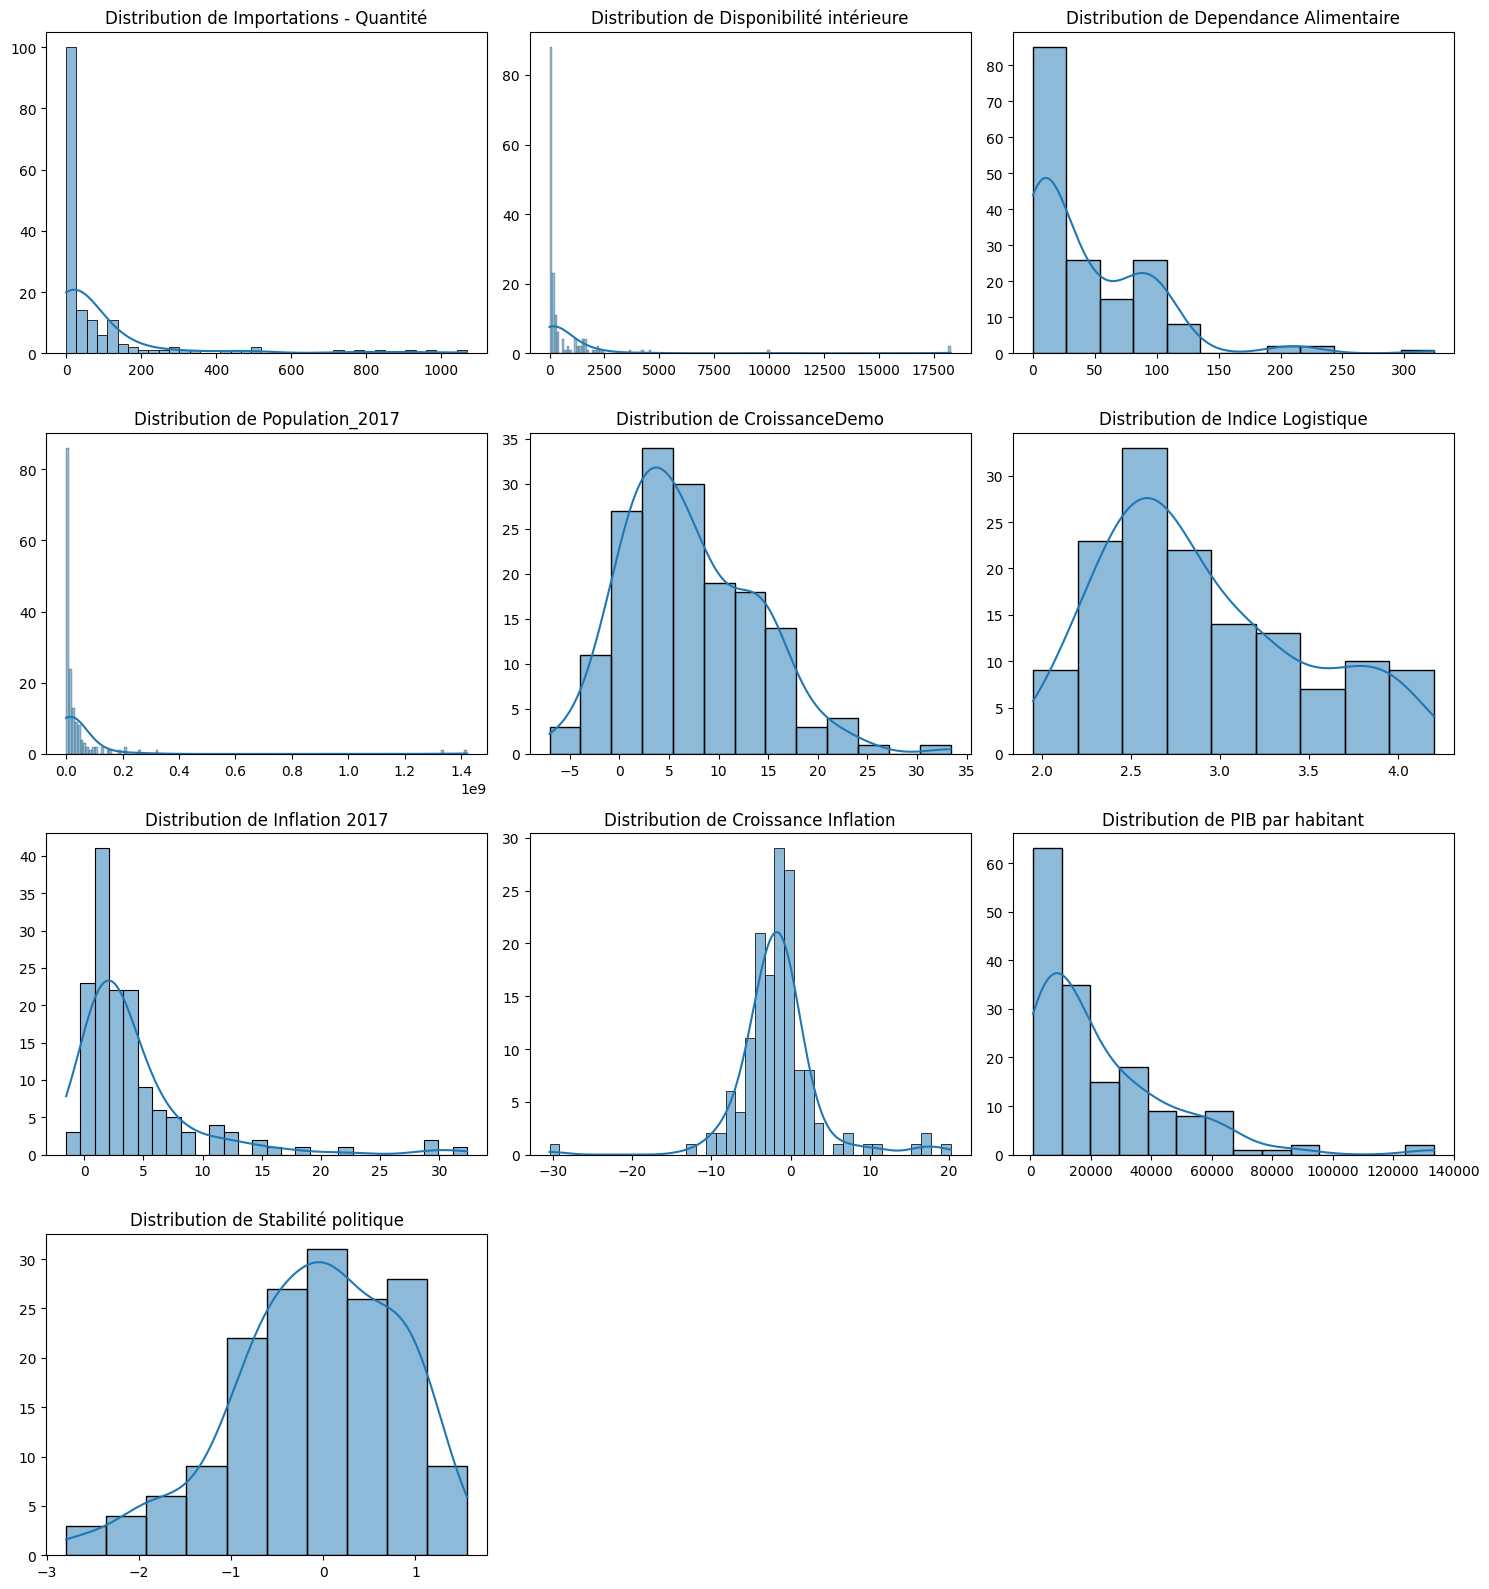

In [ ]:
#Visulatisation de la distribution
import math

cols_per_row = 3
rows = math.ceil(len(numeric_cols) / cols_per_row)

plt.figure(figsize=(15, rows * 4))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(rows, cols_per_row, i)
    sns.histplot(Fichier_clean[col].dropna(), kde=True)
    plt.title(f"Distribution de {col}")
    plt.xlabel("")
    plt.ylabel("")

plt.tight_layout()
plt.show()

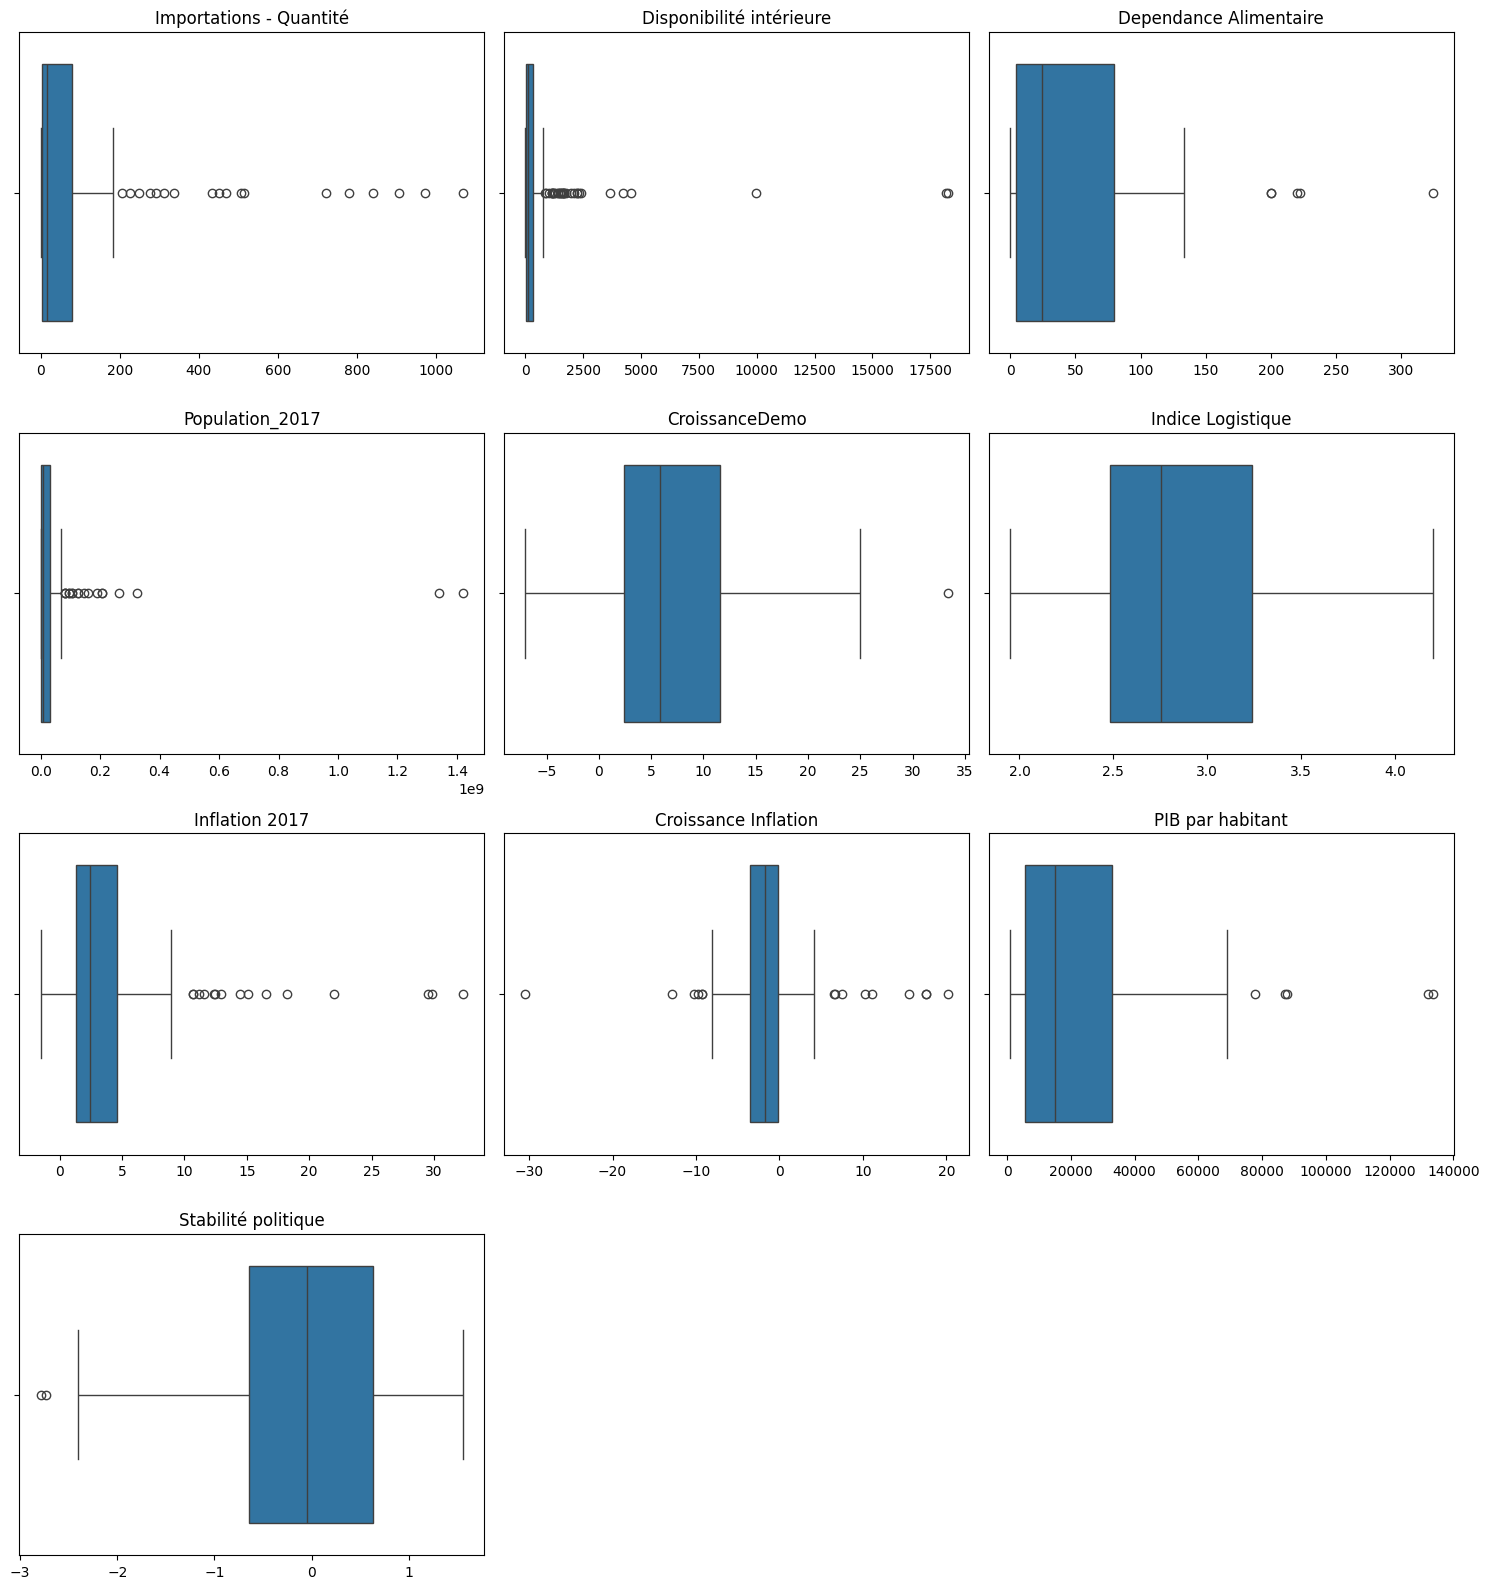

In [ ]:
#Tracer des Boxplots
import math

# Nombre de colonnes par ligne
cols_per_row = 3

# Nombre de lignes nécessaires
rows = math.ceil(len(numeric_cols) / cols_per_row)

plt.figure(figsize=(15, rows * 4))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(rows, cols_per_row, i)
    sns.boxplot(x=Fichier_clean[col])
    plt.title(col)
    plt.xlabel("")

plt.tight_layout()
plt.show()

In [ ]:
print("=== Détection des outliers avec valeurs correspondantes ===\n")

for col in numeric_cols:
    # Calcul des quartiles
    Q1 = Fichier_clean[col].quantile(0.25)
    Q3 = Fichier_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    # Bornes d'outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Extraction des outliers
    outliers = Fichier_clean[
        (Fichier_clean[col] < lower_bound) | (Fichier_clean[col] > upper_bound)
    ][['Pays', col]]

    # Affichage
    if outliers.empty:
        print(f"Aucun outlier détecté dans la colonne '{col}'.\n")
    else:
        print(f"Outliers détectés dans la colonne '{col}' :")
        for _, row in outliers.iterrows():
            print(f"- {row['Pays']} : {row[col]}")
        print("\n")

=== Détection des outliers avec valeurs correspondantes ===

Outliers détectés dans la colonne 'Importations - Quantité' :
- Afrique du Sud : 514.0
- Allemagne : 842.0
- Angola : 277.0
- Arabie saoudite : 722.0
- Belgique : 338.0
- Chine - RAS de Hong-Kong : 907.0
- Chine, continentale : 452.0
- Cuba : 312.0
- Espagne : 205.0
- France : 506.0
- Fédération de Russie : 226.0
- Iraq : 470.0
- Japon : 1069.0
- Mexique : 972.0
- Philippines : 249.0
- Royaume-Uni de Grande-Bretagne et d'Irlande du Nord : 779.0
- Viet Nam : 291.0
- Émirats arabes unis : 433.0


Outliers détectés dans la colonne 'Disponibilité intérieure' :
- Afrique du Sud : 2118.0
- Allemagne : 1739.0
- Arabie saoudite : 1435.0
- Argentine : 1962.0
- Australie : 1171.0
- Brésil : 9982.0
- Canada : 1433.0
- Chine, continentale : 18161.0
- Colombie : 1643.0
- Espagne : 1497.0
- France : 1573.0
- Fédération de Russie : 4556.0
- Inde : 3661.0
- Indonésie : 2323.0
- Iran : 2220.0
- Italie : 1173.0
- Japon : 2415.0
- Malaisie : 16

Ces Outliers me semblent cohérent, nous n'allons donc pas faire de traitement dessus

In [ ]:
#Exporter le DF Fichier_clean
#Fichier_clean.to_csv('/content/drive/MyDrive/Projet_11_data/Fichier_clean.csv', index=False)

